<a href="https://colab.research.google.com/github/KruthikaVirupakshappa/DATA266-Lab1-Pair37/blob/jiayi-work/task2_sentiment/jiayi/src/Task2_Yelp_Sentiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [18]:
import json
from pathlib import Path

MEMBER_NAME = "jiayi"
config_path = Path("task2_sentiment") / MEMBER_NAME / "config.json"

with open(config_path, "r") as f:
    config = json.load(f)

SID4         = 4253  # last four digits of your SJSU ID
SEED         = config["seed"] # torch.manual_seed, np.random.seed, random_state
SLICE        = SID4 % 1000   # start index of your dataset subset
HP_ID        = SID4 % 6      # your assigned hyperparameter arm, Table 0.1
CLS_A, CLS_B = (SID4 % 10), ((SID4 // 10) % 10)   # your two focus classes

MAX_VOCAB_SIZE = config["preprocessing"]["max_vocab_size"]
MIN_FREQ = config["preprocessing"]["min_freq"]
p = config["preprocessing"]["length_percentile"]
cap = config["preprocessing"]["max_len_cap"]
BATCH_SIZE = config["baseline"]["batch_size"]
EMBED_DIM = config["baseline"]["embedding_dim"]
LEARNING_RATE = config["baseline"]["learning_rate"]
EPOCHS = config["baseline"]["epochs"]
EXP1_EMBED_DIM = config["experiment_1"]["embedding_dim"]
EXP1_HIDDEN_DIM_1 = config["experiment_1"]["hidden_dim_1"]
EXP1_HIDDEN_DIM_2 = config["experiment_1"]["hidden_dim_2"]
EXP1_DROPOUT = config["experiment_1"]["dropout"]
EXP1_BATCH_SIZE = config["experiment_1"]["batch_size"]
EXP1_LEARNING_RATE = config["experiment_1"]["learning_rate"]
EXP1_EPOCHS = config["experiment_1"]["epochs"]
EXP2_EMBED_DIM = config["experiment_2"]["embedding_dim"]
EXP2_ATTENTION_DIM = config["experiment_2"]["attention_dim"]
EXP2_BATCH_SIZE = config["experiment_2"]["batch_size"]
EXP2_LEARNING_RATE = config["experiment_2"]["learning_rate"]
EXP2_EPOCHS = config["experiment_2"]["epochs"]
POOLING = config["baseline"]["pooling"]

In [ ]:
print(f"SID4: {SID4}, SEED: {SEED}, SLICE: {SLICE}, HP_ID: {HP_ID}, CLS_A, CLS_B: {CLS_A}, {CLS_B}")

SID4: 4253, SEED: 4253, SLICE: 253, HP_ID: 5, CLS_A, CLS_B: 3, 5


### Data Preprocessing

In [ ]:
!pip install -q nltk

In [16]:
import random
import numpy as np
import torch
from pathlib import Path
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
import math
import torch.nn as nn
import torch.nn.functional as F
import time
import matplotlib.pyplot as plt
from datetime import datetime
import platform
from zoneinfo import ZoneInfo
import subprocess
import sys
from tqdm.auto import tqdm
import re
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from nltk.stem import PorterStemmer
from collections import Counter
from datasets import load_from_disk
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, precision_recall_curve, auc, average_precision_score, matthews_corrcoef, brier_score_loss, f1_score, ConfusionMatrixDisplay
from scipy.stats import binomtest
import json

In [19]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
# load shared data from download_.py

dataset_folder = Path("task2_sentiment/data/yelp_polarity")
data = load_from_disk(str(dataset_folder))

# inspect the original dataset
print(data)
print(data.keys())
print(data["train"].features)
print(data["train"][0])

In [ ]:
# check and handle missing/malformed text or labels.
def valid_example(example):
    valid_text = isinstance(example["text"], str) and example["text"].strip() != ""
    valid_label = example["label"] in (0, 1)
    return valid_text and valid_label

train_before = len(data["train"])
test_before = len(data["test"])

train_raw = data["train"].filter(valid_example)
test_raw = data["test"].filter(valid_example)

print("Invalid train rows removed:", train_before - len(train_raw))
print("Invalid test rows removed:", test_before - len(test_raw))
print("Valid train rows:", len(train_raw))
print("Valid test rows:", len(test_raw))

Invalid train rows removed: 0
Invalid test rows removed: 0
Valid train rows: 560000
Valid test rows: 38000


Train class distribution
  label 0: 280,000 (50.00%)
  label 1: 280,000 (50.00%)


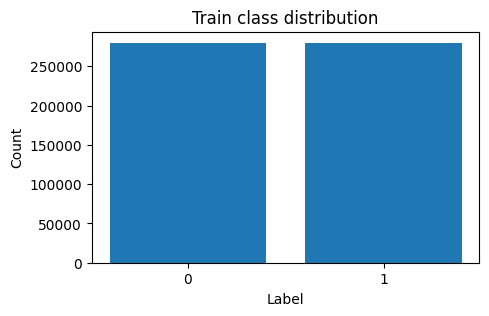

Test class distribution
  label 0: 19,000 (50.00%)
  label 1: 19,000 (50.00%)


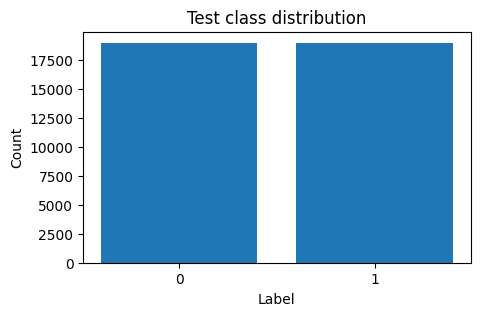

In [ ]:
# class distribution and balance
def show_class_balance(split, name):
    labels = np.array(split["label"])
    values, counts = np.unique(labels, return_counts=True)
    total = len(labels)

    print(f"{name} class distribution")
    for value, count in zip(values, counts):
        print(f"  label {value}: {count:,} ({count / total:.2%})")

    plt.figure(figsize=(5, 3))
    plt.bar(values.astype(str), counts)
    plt.title(f"{name} class distribution")
    plt.xlabel("Label")
    plt.ylabel("Count")
    plt.show()

show_class_balance(train_raw, "Train")
show_class_balance(test_raw, "Test")


p50: 97 words
p90: 282 words
p95: 372 words
p99: 608 words
mean: 133.03
max: 1052


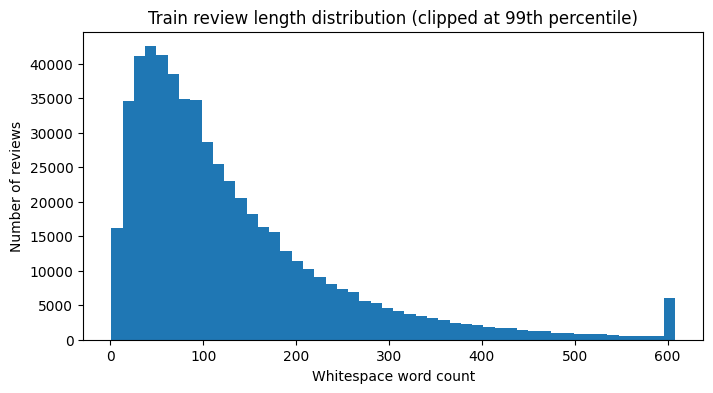

In [ ]:
# review length distribution
# Keep the official Yelp test split untouched for final evaluation

raw_train_lengths = np.array([len(text.split()) for text in train_raw["text"]])

for percentile in [50, 90, 95, 99]:
    print(f"p{percentile}: {np.percentile(raw_train_lengths, percentile):.0f} words")
print("mean:", round(raw_train_lengths.mean(), 2))
print("max:", int(raw_train_lengths.max()))

p99 = int(np.percentile(raw_train_lengths, 99))
plt.figure(figsize=(8, 4))
plt.hist(np.clip(raw_train_lengths, 0, p99), bins=50)
plt.title("Train review length distribution (clipped at 99th percentile)")
plt.xlabel("Whitespace word count")
plt.ylabel("Number of reviews")
plt.show()


Train: 504000
Validation: 56000
Test: 38000
Train split class distribution
  label 0: 252,000 (50.00%)
  label 1: 252,000 (50.00%)


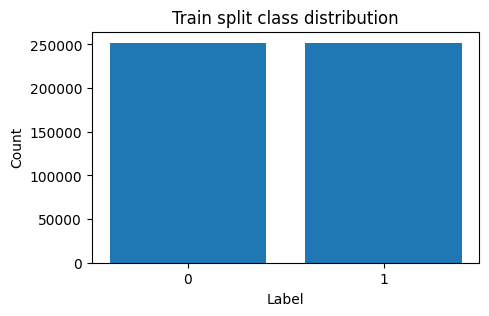

Validation split class distribution
  label 0: 28,000 (50.00%)
  label 1: 28,000 (50.00%)


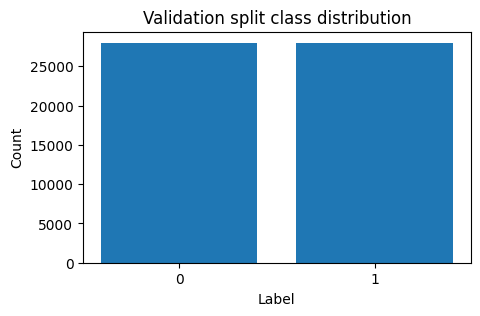

In [ ]:
# stratify by label so train/validation keep the same class balance
# Keep the official Yelp test split untouched for final evaluation

all_indices = np.arange(len(train_raw))
all_labels = np.array(train_raw["label"])

train_idx, val_idx = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=SEED,
    stratify=all_labels,
)

train_ds = train_raw.select(train_idx.tolist())
val_ds = train_raw.select(val_idx.tolist())
test_ds = test_raw

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))
show_class_balance(train_ds, "Train split")
show_class_balance(val_ds, "Validation split")

In [ ]:
# lowercasing + regex cleanup + split()
# stopword removal + stemming

STOP_WORDS = set(ENGLISH_STOP_WORDS) - {"no", "nor", "not", "never"}
stemmer = PorterStemmer()
USE_STEMMING = True


def clean_text(text):
    text = text.lower()

    # preserve common negation meaning before punctuation is removed
    text = re.sub(r"\bwon['’]t\b", "will not", text)
    text = re.sub(r"\bcan['’]t\b", "can not", text)
    text = re.sub(r"n['’]t\b", " not", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize_text(cleaned_text):
    tokens = cleaned_text.split()
    tokens = [token for token in tokens if token not in STOP_WORDS]

    if USE_STEMMING:
        tokens = [stemmer.stem(token) for token in tokens]

    return tokens


def preprocess_text(text):
    cleaned = clean_text(text)
    return tokenize_text(cleaned)


for i in range(3):
    raw = train_ds[i]["text"]
    cleaned = clean_text(raw)
    tokens = tokenize_text(cleaned)

    print("RAW:", raw[:300])
    print("CLEANED:", cleaned[:300])
    print("TOKENS:", tokens[:40])
    print("-" * 80)

RAW: Hands down the best sushi I've ever had.  The other items are amazing too - kobe beef melts in your mouth.  Honestly one of the best meals in my entire life.  The ambiance is spectacular too, and the service is impeccable.  The waitstaff are friendly and full of good recommendations.  And it's at th
CLEANED: hands down the best sushi i ve ever had the other items are amazing too kobe beef melts in your mouth honestly one of the best meals in my entire life the ambiance is spectacular too and the service is impeccable the waitstaff are friendly and full of good recommendations and it s at the hard rock h
TOKENS: ['hand', 'best', 'sushi', 've', 'item', 'amaz', 'kobe', 'beef', 'melt', 'mouth', 'honestli', 'best', 'meal', 'entir', 'life', 'ambianc', 'spectacular', 'servic', 'impecc', 'waitstaff', 'friendli', 'good', 'recommend', 's', 'hard', 'rock', 'hotel', 'stick', 'tommi', 'lee', 'did']
--------------------------------------------------------------------------------
RAW: The new ch

In [ ]:
# build a word-level vocabulary from the training split
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_counts = Counter()
processed_lengths = []

for row in tqdm(train_ds, total=len(train_ds), desc="Building vocabulary"):
    tokens = preprocess_text(row["text"])
    word_counts.update(tokens)
    processed_lengths.append(len(tokens))

word_to_idx = {PAD_TOKEN: 0, UNK_TOKEN: 1}

for word, count in word_counts.most_common(MAX_VOCAB_SIZE - 2):
    if count < MIN_FREQ:
        break
    word_to_idx[word] = len(word_to_idx)

idx_to_word = {idx: word for word, idx in word_to_idx.items()}

PAD_IDX = word_to_idx[PAD_TOKEN]
UNK_IDX = word_to_idx[UNK_TOKEN]
VOCAB_SIZE = len(word_to_idx)

print("Vocabulary size:", VOCAB_SIZE)
print("PAD index:", PAD_IDX, "UNK index:", UNK_IDX)
print("Most common words:", word_counts.most_common(20))

Building vocabulary:   0%|          | 0/504000 [00:00<?, ?it/s]

Vocabulary size: 30000
PAD index: 0 UNK index: 1
Most common words: [('not', 944567), ('n', 738899), ('s', 398289), ('place', 328537), ('food', 303181), ('good', 277031), ('like', 260575), ('time', 251013), ('just', 233251), ('order', 216211), ('did', 200601), ('servic', 195029), ('great', 189848), ('no', 171647), ('realli', 152257), ('tri', 143717), ('look', 122888), ('want', 122509), ('got', 120486), ('come', 119229)]


In [ ]:
# use only the training split to choose a fixed sequence length
# 95th percentile covers most reviews; cap at 256 to keep training manageable

processed_lengths = np.array(processed_lengths)
p_len = int(np.percentile(processed_lengths, p))
MAX_LEN = min(p_len, cap)

print("Processed-token p50:", int(np.percentile(processed_lengths, 50)))
print("Processed-token p90:", int(np.percentile(processed_lengths, 90)))
print(f"Processed-token p{p}:", p_len)
print("MAX_LEN cap:", cap)
print("Final MAX_LEN used:", MAX_LEN)

Processed-token p50: 48
Processed-token p90: 140
Processed-token p99: 301
MAX_LEN cap: 256
Final MAX_LEN used: 256


In [ ]:
# unknown words use <UNK>, and reviews are padded/truncated to MAX_LEN

def encode_tokens(tokens):
    return [word_to_idx.get(token, UNK_IDX) for token in tokens]


def encode_text(text):
    tokens = preprocess_text(text)
    ids = encode_tokens(tokens)[:MAX_LEN]
    length = len(ids)

    if length < MAX_LEN:
        ids = ids + [PAD_IDX] * (MAX_LEN - length)

    return ids, length

def encode_batch(batch):
    all_ids = []
    all_lengths = []

    for text in batch["text"]:
        ids, length = encode_text(text)
        all_ids.append(ids)
        all_lengths.append(length)

    return {
        "input_ids": all_ids,
        "length": all_lengths,
    }


train_encoded = train_ds.map(encode_batch, batched=True, batch_size=1000, desc="Encoding train")
val_encoded = val_ds.map(encode_batch, batched=True, batch_size=1000, desc="Encoding validation")
test_encoded = test_ds.map(encode_batch, batched=True, batch_size=1000, desc="Encoding test")

sample = train_encoded[0]
print("Label:", sample["label"])
print("Encoded length before padding:", sample["length"])
print("First 30 token IDs:", sample["input_ids"][:30])
print("Fixed input length:", len(sample["input_ids"]))

Encoding train:   0%|          | 0/504000 [00:00<?, ? examples/s]

Encoding validation:   0%|          | 0/56000 [00:00<?, ? examples/s]

Encoding test:   0%|          | 0/38000 [00:00<?, ? examples/s]

Label: 1
Encoded length before padding: 31
First 30 token IDs: [224, 48, 175, 25, 182, 114, 2062, 230, 824, 608, 681, 48, 86, 392, 482, 676, 1434, 13, 2586, 2124, 80, 7, 95, 4, 214, 617, 105, 644, 5437, 2828]
Fixed input length: 256


In [ ]:
# demonstration of the shape produced by a randomly initialized embedding layer

EMBED_DIM = 128
embedding = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=PAD_IDX)

sample_ids = torch.tensor([sample["input_ids"]], dtype=torch.long)
sample_emb = embedding(sample_ids)

print("Input ID shape:", sample_ids.shape)
print("Embedding output shape:", sample_emb.shape)

Input ID shape: torch.Size([1, 256])
Embedding output shape: torch.Size([1, 256, 128])


In [ ]:
# full encoded dataset can be regenerated from the raw Yelp data

processed_dir = Path("task2_sentiment") / MEMBER_NAME / "data_processed"
processed_dir.mkdir(parents=True, exist_ok=True)

with open(processed_dir / "word_to_idx.json", "w") as f:
    json.dump(word_to_idx, f)

print("Saved:")
for p in sorted(processed_dir.iterdir()):
    print(" -", p)


Saved:
 - task2_sentiment/jiayi/data_processed/word_to_idx.json


In [ ]:
# to be delete later
from datasets import load_from_disk
import json
from pathlib import Path

# Parent folder
drive_dir = Path(
    "/content/drive/MyDrive/DATA266_Lab1/task2_yelp_processed"
)

# Load the corrected 185-token encoded dataset
encoded_dataset = load_from_disk(
    str(drive_dir / "encoded_dataset_185")
)

train_encoded = encoded_dataset["train"]
val_encoded = encoded_dataset["validation"]
test_encoded = encoded_dataset["test"]

# Load the vocabulary
with open(drive_dir / "word_to_idx.json", "r") as f:
    word_to_idx = json.load(f)

PAD_IDX = word_to_idx["<PAD>"]
UNK_IDX = word_to_idx["<UNK>"]
VOCAB_SIZE = len(word_to_idx)

# Read the actual saved sequence length
MAX_LEN = len(train_encoded[0]["input_ids"])

print("Train:", len(train_encoded))
print("Validation:", len(val_encoded))
print("Test:", len(test_encoded))
print("Vocabulary size:", VOCAB_SIZE)
print("MAX_LEN:", MAX_LEN)

Train: 504000
Validation: 56000
Test: 38000
Vocabulary size: 30000
MAX_LEN: 185


## Model

In [ ]:
class YelpDataset(Dataset):
    def __init__(self, encoded_data):
        self.data = encoded_data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data[idx]

        input_ids = torch.tensor(row["input_ids"], dtype=torch.long)

        label = torch.tensor([row["label"]], dtype=torch.float32)

        return input_ids, label


train_dataset = YelpDataset(train_encoded)
val_dataset = YelpDataset(val_encoded)
test_dataset = YelpDataset(test_encoded)

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

### Baseline Mean Embedding

In [ ]:
class MeanMaxEmbeddingClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, pad_idx):
        super().__init__()

        self.pad_idx = pad_idx

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=pad_idx
        )

        self.fc = nn.Linear(embed_dim * 2, 1)
        self.activation = nn.Sigmoid()

    def forward(self, input_ids):
        # [B, T] -> [B, T, E]
        x = self.embedding(input_ids)

        # True for real tokens, False for PAD
        # [B, T] -> [B, T, 1]
        mask = (input_ids != self.pad_idx).unsqueeze(-1)
        mask_float = mask.float()

        # masked mean pooling
        summed = (x * mask_float).sum(dim=1)
        lengths = mask_float.sum(dim=1).clamp(min=1)
        mean_pooled = summed / lengths

        # masked max pooling
        max_input = x.masked_fill(~mask, -1e9)
        max_pooled = max_input.max(dim=1).values

        # [B, E] + [B, E] -> [B, 2E]
        pooled = torch.cat([mean_pooled, max_pooled], dim=1)

        # [B, 2E] -> [B, 1]
        output = self.activation(self.fc(pooled))

        return output

In [ ]:
# Reset randomness for the official training run
set_seed(SEED)

# Fresh seeded DataLoader for reproducible shuffling
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Clean model for the training run
baseline_model = MeanMaxEmbeddingClassifier(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    pad_idx=PAD_IDX
).to(device)

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

parameter_count = sum(p.numel() for p in baseline_model.parameters())

print("Mean+Max baseline model ready")
print("Parameters:", parameter_count)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)

Mean+Max baseline model ready
Parameters: 3840257
Batch size: 64
Learning rate: 0.001
Epochs: 5


In [ ]:
# raw log setup
log_dir = Path("reproducibility/raw_logs")
log_dir.mkdir(parents=True, exist_ok=True)

LA_TZ = ZoneInfo("America/Los_Angeles")
run_timestamp = datetime.now(LA_TZ).strftime("%Y%m%d_%H%M%S")

train_log_path = log_dir / f"task2_{MEMBER_NAME}_baseline_meanmax_train_{run_timestamp}.log"

# x prevents accidentally overwriting an old raw log
log_file = open(train_log_path, "x", encoding="utf-8")


def log(message):
    timestamp = datetime.now(LA_TZ).strftime("%Y-%m-%d %H:%M:%S %Z")
    line = f"[{timestamp}] {message}"

    print(line)
    log_file.write(line + "\n")
    log_file.flush()


# hardware

def get_cpu_name():
    try:
        result = subprocess.run(["lscpu"], capture_output=True, text=True, check=True)

        for line in result.stdout.splitlines():
            if line.startswith("Model name:"):
                return line.split(":", 1)[1].strip()

    except Exception:
        pass

    return platform.processor() or platform.machine()


cpu_name = get_cpu_name()
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU"


# run info
log("Task 2 Yelp Mean+Max Embedding Baseline Full Training")

log(f"Config file: {config_path}")
log(f"Baseline config: {json.dumps(config['baseline'], sort_keys=True)}")

log(f"Seed: {SEED}")
log(f"Device: {device}")
log(f"CPU: {cpu_name}")
log(f"GPU: {gpu_name}")

log(f"Python version: {platform.python_version()}")
log(f"PyTorch version: {torch.__version__}")
log(f"CUDA version: {torch.version.cuda}")

log(f"Train examples: {len(train_dataset)}")
log(f"Validation examples: {len(val_dataset)}")

log(f"Vocabulary size: {VOCAB_SIZE}")
log(f"Sequence length: {MAX_LEN}")
log(f"Embedding dimension: {EMBED_DIM}")
log(f"Pooling: {POOLING}")
log(f"Classifier: Linear({EMBED_DIM * 2}, 1) -> Sigmoid")

log(f"Batch size: {BATCH_SIZE}")
log(f"Epochs: {EPOCHS}")
log("Optimizer: Adam")
log(f"Learning rate: {LEARNING_RATE}")
log("Loss: BCELoss")

log(f"Parameter count: {parameter_count}")

[2026-10-04 23:48:03 PDT] Task 2 Yelp Mean+Max Embedding Baseline Full Training
[2026-10-04 23:48:03 PDT] Config file: task2_sentiment/jiayi/config.json
[2026-10-04 23:48:03 PDT] Baseline config: {"batch_size": 64, "embedding_dim": 128, "epochs": 5, "learning_rate": 0.001}
[2026-10-04 23:48:03 PDT] Seed: 4253
[2026-10-04 23:48:03 PDT] Device: cuda
[2026-10-04 23:48:03 PDT] CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
[2026-10-04 23:48:03 PDT] GPU: NVIDIA A100-SXM4-40GB
[2026-10-04 23:48:03 PDT] Python version: 3.13.15
[2026-10-04 23:48:03 PDT] PyTorch version: 2.11.0+cu130
[2026-10-04 23:48:03 PDT] CUDA version: 13.0
[2026-10-04 23:48:03 PDT] Train examples: 504000
[2026-10-04 23:48:03 PDT] Validation examples: 56000
[2026-10-04 23:48:03 PDT] Vocabulary size: 30000
[2026-10-04 23:48:03 PDT] Sequence length: 185
[2026-10-04 23:48:03 PDT] Embedding dimension: 128
[2026-10-04 23:48:03 PDT] Pooling: Masked Mean + Masked Max
[2026-10-04 23:48:03 PDT] Classifier: Linear(256, 1) -> Sigmoid
[2026-10-04

In [ ]:
# checkpoint folders
output_dir = Path("task2_sentiment") / MEMBER_NAME / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_dir = Path("task2_sentiment") / MEMBER_NAME / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

best_checkpoint_path = checkpoint_dir / f"task2_baseline_meanmax_best_{run_timestamp}.pt"

train_losses = []
val_losses = []

best_val_loss = float("inf")
total_train_examples = 0
total_train_seconds = 0.0

if device.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

run_start = time.perf_counter()


for ep in range(EPOCHS):
    # train
    baseline_model.train()

    total_train_loss = 0.0
    train_example_count = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_start = time.perf_counter()

    for batch_ids, batch_labels in train_loader:
        batch_ids = batch_ids.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = baseline_model(batch_ids)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        batch_size = batch_labels.size(0)
        total_train_loss += loss.item() * batch_size
        train_example_count += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_seconds = time.perf_counter() - epoch_train_start
    avg_train_loss = total_train_loss / train_example_count
    train_losses.append(avg_train_loss)

    epoch_examples_per_sec = train_example_count / epoch_train_seconds
    total_train_examples += train_example_count
    total_train_seconds += epoch_train_seconds

    # validation

    baseline_model.eval()

    total_val_loss = 0.0
    val_example_count = 0

    with torch.no_grad():
        for batch_ids, batch_labels in val_loader:
            batch_ids = batch_ids.to(device)
            batch_labels = batch_labels.to(device)

            outputs = baseline_model(batch_ids)
            loss = criterion(outputs, batch_labels)

            batch_size = batch_labels.size(0)
            total_val_loss += loss.item() * batch_size
            val_example_count += batch_size

    avg_val_loss = total_val_loss / val_example_count
    val_losses.append(avg_val_loss)

    # Save best checkpoint

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        torch.save(
            {
                "run_id": run_timestamp,
                "epoch": ep + 1,
                "model_state_dict": baseline_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": avg_train_loss,
                "val_loss": avg_val_loss,
                "vocab_size": VOCAB_SIZE,
                "embedding_dim": EMBED_DIM,
                "pooling": POOLING,
                "pad_idx": PAD_IDX,
                "max_len": MAX_LEN,
                "config": config["baseline"]
            },
            best_checkpoint_path
        )

        log(
            f"Saved new best checkpoint: epoch={ep + 1}, "
            f"val_loss={avg_val_loss:.4f}, "
            f"path={best_checkpoint_path}"
        )

    log(
        f"Epoch {ep + 1}/{EPOCHS}, "
        f"Train Loss: {avg_train_loss:.4f}, "
        f"Val Loss: {avg_val_loss:.4f}, "
        f"Train Time: {epoch_train_seconds:.2f}s, "
        f"Examples/s: {epoch_examples_per_sec:.2f}"
    )


# final training statistics

if device.type == "cuda":
    torch.cuda.synchronize()
    peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
else:
    peak_memory_mb = 0.0

total_run_time = time.perf_counter() - run_start
overall_examples_per_sec = total_train_examples / total_train_seconds

log(f"Total Training Time: {total_train_seconds:.2f} s")
log(f"Total Run Time: {total_run_time:.2f} s")
log(f"Overall Training Examples/s: {overall_examples_per_sec:.2f}")
log(f"Peak GPU Memory: {peak_memory_mb:.2f} MB")
log(f"Best Validation Loss: {best_val_loss:.4f}")
log(f"Best Checkpoint: {best_checkpoint_path}")
log("Training completed successfully.")

log_file.close()

[2026-10-04 23:50:17 PDT] Saved new best checkpoint: epoch=1, val_loss=0.2070, path=task2_sentiment/jiayi/checkpoints/task2_baseline_meanmax_best_20261004_234803.pt
[2026-10-04 23:50:17 PDT] Epoch 1/5, Train Loss: 0.2424, Val Loss: 0.2070, Train Time: 110.80s, Examples/s: 4548.55
[2026-10-04 23:52:14 PDT] Saved new best checkpoint: epoch=2, val_loss=0.2008, path=task2_sentiment/jiayi/checkpoints/task2_baseline_meanmax_best_20261004_234803.pt
[2026-10-04 23:52:14 PDT] Epoch 2/5, Train Loss: 0.1905, Val Loss: 0.2008, Train Time: 105.71s, Examples/s: 4767.71
[2026-10-04 23:54:10 PDT] Saved new best checkpoint: epoch=3, val_loss=0.2000, path=task2_sentiment/jiayi/checkpoints/task2_baseline_meanmax_best_20261004_234803.pt
[2026-10-04 23:54:10 PDT] Epoch 3/5, Train Loss: 0.1777, Val Loss: 0.2000, Train Time: 105.61s, Examples/s: 4772.17
[2026-10-04 23:56:06 PDT] Saved new best checkpoint: epoch=4, val_loss=0.1952, path=task2_sentiment/jiayi/checkpoints/task2_baseline_meanmax_best_20261004_23

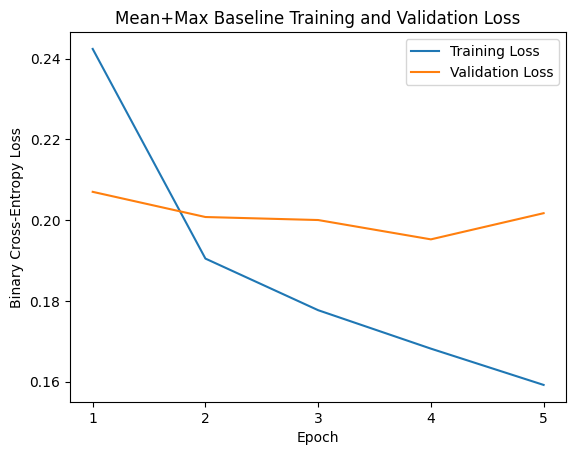

Saved loss curve: task2_sentiment/jiayi/outputs/baseline_meanmax_loss_curve_20261004_234803.png


In [ ]:
loss_curve_path = output_dir / f"baseline_meanmax_loss_curve_{run_timestamp}.png"

epochs = range(1, len(train_losses) + 1)

plt.figure()
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Mean+Max Baseline Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.savefig(loss_curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved loss curve:", loss_curve_path)

In [ ]:
manifest_dir = Path("reproducibility/manifests")
manifest_dir.mkdir(parents=True, exist_ok=True)

# package environment
environment_path = manifest_dir / f"task2_{MEMBER_NAME}_baseline_meanmax_environment_{run_timestamp}.txt"

with open(environment_path, "w") as f:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=f,
        text=True,
        check=True
    )

# manifest
manifest = {
    "task": "task2_sentiment",
    "model": "baseline_meanmax_embedding",
    "member": MEMBER_NAME,
    "run_id": run_timestamp,
    "architecture": "Embedding -> Masked Mean Pooling + Masked Max Pooling -> Concatenate -> Linear -> Sigmoid",
    "config_file": str(config_path),
    "config": config["baseline"],
    "raw_log": str(train_log_path),

    "best_checkpoint": str(best_checkpoint_path),
    "best_val_loss": float(best_val_loss),
    "loss_curve": str(loss_curve_path),

    "cpu": cpu_name,
    "gpu": gpu_name,

    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,

    "parameter_count": parameter_count,
    "training_time_sec": total_train_seconds,
    "examples_per_sec": overall_examples_per_sec,
    "peak_gpu_memory_mb": peak_memory_mb,

    "environment_file": str(environment_path),

    "metrics_report": str(
        Path("task2_sentiment") / MEMBER_NAME / "metrics_report.csv"
    )
}

manifest_path = manifest_dir / f"task2_{MEMBER_NAME}_baseline_meanmax_manifest_{run_timestamp}.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("Saved raw log:", train_log_path)
print("Saved checkpoint:", best_checkpoint_path)
print("Saved manifest:", manifest_path)
print("Saved environment:", environment_path)

Saved raw log: reproducibility/raw_logs/task2_jiayi_baseline_meanmax_train_20261004_234803.log
Saved checkpoint: task2_sentiment/jiayi/checkpoints/task2_baseline_meanmax_best_20261004_234803.pt
Saved manifest: reproducibility/manifests/task2_jiayi_baseline_meanmax_manifest_20261004_234803.json
Saved environment: reproducibility/manifests/task2_jiayi_baseline_meanmax_environment_20261004_234803.txt


### Experiment 1 MLP

In [ ]:
class MeanEmbeddingMLPClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim_1, hidden_dim_2, dropout, pad_idx):
        super().__init__()

        self.pad_idx = pad_idx

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)

        self.fc1 = nn.Linear(embed_dim, hidden_dim_1)
        self.fc2 = nn.Linear(hidden_dim_1, hidden_dim_2)
        self.fc3 = nn.Linear(hidden_dim_2, 1)

        self.dropout = nn.Dropout(dropout)
        self.activation = nn.Sigmoid()

    def forward(self, input_ids):
        # [B, T] -> [B, T, E]
        x = self.embedding(input_ids)

        # 1 for real tokens, 0 for PAD
        # [B, T] -> [B, T, 1]
        mask = (input_ids != self.pad_idx).unsqueeze(-1).float()

        # ignore PAD embeddings
        x = x * mask

        # [B, T, E] -> [B, E]
        summed = x.sum(dim=1)

        # [B, T, 1] -> [B, 1]
        lengths = mask.sum(dim=1).clamp(min=1)

        # mean embedding for each review
        # [B, E] / [B, 1] -> [B, E]
        x = summed / lengths

        # MLP classifier
        # [B, 128] -> [B, 64] -> [B, 32] -> [B, 1]
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = torch.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.activation(self.fc3(x))

        return x

In [ ]:
import gc

# Free the completed baseline run from GPU memory
if "baseline_model" in globals():
    del baseline_model

if "optimizer" in globals():
    del optimizer

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Reset randomness for the official Experiment 1 run
set_seed(SEED)

# Fresh seeded DataLoader for reproducible shuffling
exp1_generator = torch.Generator()
exp1_generator.manual_seed(SEED)

exp1_train_loader = DataLoader(train_dataset, batch_size=EXP1_BATCH_SIZE, shuffle=True, generator=exp1_generator)
exp1_val_loader = DataLoader(val_dataset, batch_size=EXP1_BATCH_SIZE, shuffle=False)

# Fresh Experiment 1 model
exp1_model = MeanEmbeddingMLPClassifier(
    vocab_size=VOCAB_SIZE,
    embed_dim=EXP1_EMBED_DIM,
    hidden_dim_1=EXP1_HIDDEN_DIM_1,
    hidden_dim_2=EXP1_HIDDEN_DIM_2,
    dropout=EXP1_DROPOUT,
    pad_idx=PAD_IDX
).to(device)

exp1_criterion = nn.BCELoss()
exp1_optimizer = torch.optim.Adam(exp1_model.parameters(), lr=EXP1_LEARNING_RATE)

exp1_parameter_count = sum(p.numel() for p in exp1_model.parameters())

print(exp1_model)
print("Experiment 1 model ready")
print("Parameters:", exp1_parameter_count)
print("Batch size:", EXP1_BATCH_SIZE)
print("Learning rate:", EXP1_LEARNING_RATE)
print("Epochs:", EXP1_EPOCHS)

MeanEmbeddingMLPClassifier(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (activation): Sigmoid()
)
Experiment 1 model ready
Parameters: 3850369
Batch size: 64
Learning rate: 0.001
Epochs: 5


In [ ]:
# Experiment 1 run setup

exp1_output_dir = Path("task2_sentiment") / MEMBER_NAME / "outputs"
exp1_output_dir.mkdir(parents=True, exist_ok=True)

exp1_checkpoint_dir = Path("task2_sentiment") / MEMBER_NAME / "checkpoints"
exp1_checkpoint_dir.mkdir(parents=True, exist_ok=True)

exp1_log_dir = Path("reproducibility/raw_logs")
exp1_log_dir.mkdir(parents=True, exist_ok=True)

exp1_manifest_dir = Path("reproducibility/manifests")
exp1_manifest_dir.mkdir(parents=True, exist_ok=True)

LA_TZ = ZoneInfo("America/Los_Angeles")
exp1_run_timestamp = datetime.now(LA_TZ).strftime("%Y%m%d_%H%M%S")

exp1_train_log_path = exp1_log_dir / f"task2_{MEMBER_NAME}_experiment1_mlp_train_{exp1_run_timestamp}.log"
exp1_environment_path = exp1_manifest_dir / f"task2_{MEMBER_NAME}_experiment1_mlp_environment_{exp1_run_timestamp}.txt"
exp1_best_checkpoint_path = exp1_checkpoint_dir / f"task2_experiment1_mlp_best_{exp1_run_timestamp}.pt"

# Save package environment before training
with open(exp1_environment_path, "w") as f:
    subprocess.run([sys.executable, "-m", "pip", "freeze"], stdout=f, text=True, check=True)

# x prevents accidentally overwriting an old raw log
exp1_log_file = open(exp1_train_log_path, "x", encoding="utf-8")

def exp1_log(message):
    timestamp = datetime.now(LA_TZ).strftime("%Y-%m-%d %H:%M:%S %Z")
    line = f"[{timestamp}] {message}"
    print(line)
    exp1_log_file.write(line + "\n")
    exp1_log_file.flush()

def get_cpu_name():
    try:
        result = subprocess.run(["lscpu"], capture_output=True, text=True, check=True)
        for line in result.stdout.splitlines():
            if line.startswith("Model name:"):
                return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or platform.machine()

exp1_cpu_name = get_cpu_name()
exp1_gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU"

exp1_log("Task 2 Yelp Experiment 1 Mean Embedding MLP Full Training")
exp1_log(f"Config file: {config_path}")
exp1_log(f"Experiment 1 config: {json.dumps(config, sort_keys=True)}")
exp1_log("Architecture: Embedding -> Masked Mean Pooling -> Linear(128,64) -> ReLU -> Dropout(0.3) -> Linear(64,32) -> ReLU -> Dropout(0.3) -> Linear(32,1) -> Sigmoid")
exp1_log("Embedding learned from scratch: True")

exp1_log(f"Seed: {SEED}")
exp1_log(f"Device: {device}")
exp1_log(f"CPU: {exp1_cpu_name}")
exp1_log(f"GPU: {exp1_gpu_name}")

exp1_log(f"Python version: {platform.python_version()}")
exp1_log(f"PyTorch version: {torch.__version__}")
exp1_log(f"CUDA version: {torch.version.cuda}")
exp1_log(f"Environment file: {exp1_environment_path}")

exp1_log(f"Train examples: {len(train_dataset)}")
exp1_log(f"Validation examples: {len(val_dataset)}")
exp1_log(f"Vocabulary size: {VOCAB_SIZE}")
exp1_log(f"Sequence length: {MAX_LEN}")

exp1_log(f"Embedding dimension: {EXP1_EMBED_DIM}")
exp1_log(f"Hidden dimension 1: {EXP1_HIDDEN_DIM_1}")
exp1_log(f"Hidden dimension 2: {EXP1_HIDDEN_DIM_2}")
exp1_log(f"Dropout: {EXP1_DROPOUT}")

exp1_log(f"Batch size: {EXP1_BATCH_SIZE}")
exp1_log(f"Epochs: {EXP1_EPOCHS}")
exp1_log("Optimizer: Adam")
exp1_log(f"Learning rate: {EXP1_LEARNING_RATE}")
exp1_log("Loss: BCELoss")
exp1_log(f"Parameter count: {exp1_parameter_count}")

[2026-10-02 21:16:29 PDT] Task 2 Yelp Experiment 1 Mean Embedding MLP Full Training
[2026-10-02 21:16:29 PDT] Config file: task2_sentiment/jiayi/config.json
[2026-10-02 21:16:29 PDT] Experiment 1 config: {"baseline": {"batch_size": 64, "embedding_dim": 128, "epochs": 5, "learning_rate": 0.001}, "data": {"data_dir": "task2_sentiment/data/yelp_polarity", "val_size": 0.1}, "experiment_1": {"batch_size": 64, "dropout": 0.3, "embedding_dim": 128, "epochs": 5, "hidden_dim_1": 64, "hidden_dim_2": 32, "learning_rate": 0.001}, "experiment_2": {"batch_size": 64, "embedding_dim": 128, "epochs": 5, "learning_rate": 0.001}, "preprocessing": {"length_percentile": 95, "lowercase": true, "max_len_cap": 256, "max_vocab_size": 30000, "min_freq": 2, "remove_punctuation": true, "remove_stopwords": true, "stemming": true}, "seed": 4253}
[2026-10-02 21:16:29 PDT] Architecture: Embedding -> Masked Mean Pooling -> Linear(128,64) -> ReLU -> Dropout(0.3) -> Linear(64,32) -> ReLU -> Dropout(0.3) -> Linear(32,1) 

In [ ]:
exp1_train_losses = []
exp1_val_losses = []

exp1_best_val_loss = float("inf")
exp1_best_epoch = None
exp1_total_train_examples = 0
exp1_total_train_seconds = 0.0

if device.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

exp1_run_start = time.perf_counter()

for ep in range(EXP1_EPOCHS):
    # train
    exp1_model.train()

    total_train_loss = 0.0
    train_example_count = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_start = time.perf_counter()

    for batch_ids, batch_labels in exp1_train_loader:
        batch_ids = batch_ids.to(device)
        batch_labels = batch_labels.to(device)

        exp1_optimizer.zero_grad()

        outputs = exp1_model(batch_ids)
        loss = exp1_criterion(outputs, batch_labels)

        loss.backward()
        exp1_optimizer.step()

        batch_size = batch_labels.size(0)
        total_train_loss += loss.item() * batch_size
        train_example_count += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_seconds = time.perf_counter() - epoch_train_start
    avg_train_loss = total_train_loss / train_example_count
    exp1_train_losses.append(avg_train_loss)

    epoch_examples_per_sec = train_example_count / epoch_train_seconds
    exp1_total_train_examples += train_example_count
    exp1_total_train_seconds += epoch_train_seconds

    # validation
    exp1_model.eval()

    total_val_loss = 0.0
    val_example_count = 0

    with torch.no_grad():
        for batch_ids, batch_labels in exp1_val_loader:
            batch_ids = batch_ids.to(device)
            batch_labels = batch_labels.to(device)

            outputs = exp1_model(batch_ids)
            loss = exp1_criterion(outputs, batch_labels)

            batch_size = batch_labels.size(0)
            total_val_loss += loss.item() * batch_size
            val_example_count += batch_size

    avg_val_loss = total_val_loss / val_example_count
    exp1_val_losses.append(avg_val_loss)

    # Save best checkpoint
    if avg_val_loss < exp1_best_val_loss:
        exp1_best_val_loss = avg_val_loss
        exp1_best_epoch = ep + 1

        torch.save(
            {
                "run_id": exp1_run_timestamp,
                "epoch": exp1_best_epoch,
                "model_name": "MeanEmbeddingMLPClassifier",
                "model_state_dict": exp1_model.state_dict(),
                "optimizer_state_dict": exp1_optimizer.state_dict(),
                "train_loss": avg_train_loss,
                "val_loss": avg_val_loss,
                "vocab_size": VOCAB_SIZE,
                "embedding_dim": EXP1_EMBED_DIM,
                "hidden_dim_1": EXP1_HIDDEN_DIM_1,
                "hidden_dim_2": EXP1_HIDDEN_DIM_2,
                "dropout": EXP1_DROPOUT,
                "pad_idx": PAD_IDX,
                "max_len": MAX_LEN,
                "config": config
            },
            exp1_best_checkpoint_path
        )

        exp1_log(f"Saved new best checkpoint: epoch={exp1_best_epoch}, val_loss={avg_val_loss:.4f}, path={exp1_best_checkpoint_path}")

    exp1_log(f"Epoch {ep + 1}/{EXP1_EPOCHS}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, Train Time: {epoch_train_seconds:.2f}s, Examples/s: {epoch_examples_per_sec:.2f}")

# final training statistics
if device.type == "cuda":
    torch.cuda.synchronize()
    exp1_peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
else:
    exp1_peak_memory_mb = 0.0

exp1_total_run_time = time.perf_counter() - exp1_run_start
exp1_overall_examples_per_sec = exp1_total_train_examples / exp1_total_train_seconds

exp1_log(f"Total Training Time: {exp1_total_train_seconds:.2f} s")
exp1_log(f"Total Run Time: {exp1_total_run_time:.2f} s")
exp1_log(f"Overall Training Examples/s: {exp1_overall_examples_per_sec:.2f}")
exp1_log(f"Peak GPU Memory: {exp1_peak_memory_mb:.2f} MB")
exp1_log(f"Best Epoch: {exp1_best_epoch}")
exp1_log(f"Best Validation Loss: {exp1_best_val_loss:.4f}")
exp1_log(f"Best Checkpoint: {exp1_best_checkpoint_path}")
exp1_log("Training completed successfully.")

exp1_log_file.close()

[2026-10-02 21:18:55 PDT] Saved new best checkpoint: epoch=1, val_loss=0.1950, path=task2_sentiment/jiayi/checkpoints/task2_experiment1_mlp_best_20261002_211627.pt
[2026-10-02 21:18:55 PDT] Epoch 1/5, Train Loss: 0.2325, Val Loss: 0.1950, Train Time: 125.30s, Examples/s: 4022.41
[2026-10-02 21:21:08 PDT] Saved new best checkpoint: epoch=2, val_loss=0.1910, path=task2_sentiment/jiayi/checkpoints/task2_experiment1_mlp_best_20261002_211627.pt
[2026-10-02 21:21:08 PDT] Epoch 2/5, Train Loss: 0.1879, Val Loss: 0.1910, Train Time: 121.90s, Examples/s: 4134.50
[2026-10-02 21:23:21 PDT] Epoch 3/5, Train Loss: 0.1776, Val Loss: 0.1912, Train Time: 121.76s, Examples/s: 4139.26
[2026-10-02 21:25:34 PDT] Saved new best checkpoint: epoch=4, val_loss=0.1899, path=task2_sentiment/jiayi/checkpoints/task2_experiment1_mlp_best_20261002_211627.pt
[2026-10-02 21:25:34 PDT] Epoch 4/5, Train Loss: 0.1700, Val Loss: 0.1899, Train Time: 122.17s, Examples/s: 4125.29
[2026-10-02 21:27:47 PDT] Epoch 5/5, Train L

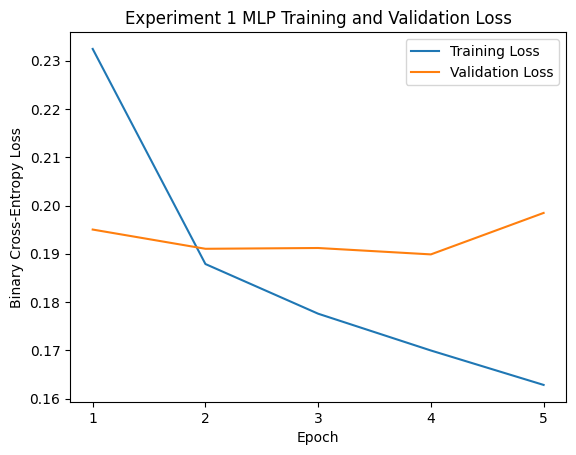

Saved loss curve: task2_sentiment/jiayi/outputs/experiment1_mlp_loss_curve_20261002_211627.png


In [ ]:
exp1_loss_curve_path = exp1_output_dir / f"experiment1_mlp_loss_curve_{exp1_run_timestamp}.png"
exp1_epochs = range(1, len(exp1_train_losses) + 1)

plt.figure()
plt.plot(exp1_epochs, exp1_train_losses, label="Training Loss")
plt.plot(exp1_epochs, exp1_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Experiment 1 MLP Training and Validation Loss")
plt.xticks(exp1_epochs)
plt.legend()
plt.savefig(exp1_loss_curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved loss curve:", exp1_loss_curve_path)

In [ ]:
exp1_manifest = {
    "task": "task2_sentiment",
    "model": "experiment1_mean_embedding_mlp",
    "member": MEMBER_NAME,
    "run_id": exp1_run_timestamp,
    "architecture": "Embedding -> Masked Mean Pooling -> Linear(128,64) -> ReLU -> Dropout(0.3) -> Linear(64,32) -> ReLU -> Dropout(0.3) -> Linear(32,1) -> Sigmoid",
    "config_file": str(config_path),
    "config": config,
    "raw_log": str(exp1_train_log_path),
    "best_checkpoint": str(exp1_best_checkpoint_path),
    "best_epoch": exp1_best_epoch,
    "best_val_loss": float(exp1_best_val_loss),
    "loss_curve": str(exp1_loss_curve_path),
    "cpu": exp1_cpu_name,
    "gpu": exp1_gpu_name,
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "parameter_count": exp1_parameter_count,
    "training_time_sec": exp1_total_train_seconds,
    "total_run_time_sec": exp1_total_run_time,
    "examples_per_sec": exp1_overall_examples_per_sec,
    "peak_gpu_memory_mb": exp1_peak_memory_mb,
    "environment_file": str(exp1_environment_path),
    "metrics_report": str(Path("task2_sentiment") / MEMBER_NAME / "metrics_report.csv")
}

exp1_manifest_path = exp1_manifest_dir / f"task2_{MEMBER_NAME}_experiment1_mlp_manifest_{exp1_run_timestamp}.json"

with open(exp1_manifest_path, "w") as f:
    json.dump(exp1_manifest, f, indent=2)

print("Saved raw log:", exp1_train_log_path)
print("Saved checkpoint:", exp1_best_checkpoint_path)
print("Saved loss curve:", exp1_loss_curve_path)
print("Saved manifest:", exp1_manifest_path)
print("Saved environment:", exp1_environment_path)

Saved raw log: reproducibility/raw_logs/task2_jiayi_experiment1_mlp_train_20261002_211627.log
Saved checkpoint: task2_sentiment/jiayi/checkpoints/task2_experiment1_mlp_best_20261002_211627.pt
Saved loss curve: task2_sentiment/jiayi/outputs/experiment1_mlp_loss_curve_20261002_211627.png
Saved manifest: reproducibility/manifests/task2_jiayi_experiment1_mlp_manifest_20261002_211627.json
Saved environment: reproducibility/manifests/task2_jiayi_experiment1_mlp_environment_20261002_211627.txt


### single head self attention

In [ ]:
class SingleHeadSelfAttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, attention_dim, max_len, pad_idx):
        super().__init__()

        self.pad_idx = pad_idx
        self.attention_dim = attention_dim

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.position_embedding = nn.Embedding(max_len, embed_dim)

        self.Wq = nn.Linear(embed_dim, attention_dim, bias=False)
        self.Wk = nn.Linear(embed_dim, attention_dim, bias=False)
        self.Wv = nn.Linear(embed_dim, attention_dim, bias=False)
        self.Wo = nn.Linear(attention_dim, attention_dim, bias=False)

        self.fc = nn.Linear(attention_dim, 1)
        self.activation = nn.Sigmoid()

    def forward(self, input_ids):
        B, T = input_ids.shape

        positions = torch.arange(T, device=input_ids.device).unsqueeze(0)
        x = self.embedding(input_ids) + self.position_embedding(positions)

        Q = self.Wq(x)
        K = self.Wk(x)
        V = self.Wv(x)

        scores = (Q @ K.transpose(-2, -1)) / math.sqrt(self.attention_dim)

        # PAD tokens cannot be attended to as keys
        valid_tokens = (input_ids != self.pad_idx)
        scores = scores.masked_fill(~valid_tokens.unsqueeze(1), -1e9)

        attn = F.softmax(scores, dim=-1)
        x = attn @ V
        x = self.Wo(x)

        # Ignore PAD query positions before pooling
        mask = valid_tokens.unsqueeze(-1).float()
        x = x * mask

        summed = x.sum(dim=1)
        lengths = mask.sum(dim=1).clamp(min=1)
        pooled = summed / lengths

        output = self.activation(self.fc(pooled))
        return output

In [ ]:
import gc

# Free completed Experiment 1 model from GPU memory
if "exp1_model" in globals():
    del exp1_model

if "exp1_optimizer" in globals():
    del exp1_optimizer

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Reset randomness for the official Experiment 2 run
set_seed(SEED)

# Fresh seeded DataLoader for reproducible shuffling
exp2_generator = torch.Generator()
exp2_generator.manual_seed(SEED)

exp2_train_loader = DataLoader(train_dataset, batch_size=EXP2_BATCH_SIZE, shuffle=True, generator=exp2_generator)
exp2_val_loader = DataLoader(val_dataset, batch_size=EXP2_BATCH_SIZE, shuffle=False)

# Fresh Experiment 2 model
exp2_model = SingleHeadSelfAttentionClassifier(
    vocab_size=VOCAB_SIZE,
    embed_dim=EXP2_EMBED_DIM,
    attention_dim=EXP2_ATTENTION_DIM,
    max_len=MAX_LEN,
    pad_idx=PAD_IDX
).to(device)

exp2_criterion = nn.BCELoss()
exp2_optimizer = torch.optim.Adam(exp2_model.parameters(), lr=EXP2_LEARNING_RATE)

exp2_parameter_count = sum(p.numel() for p in exp2_model.parameters())

print(exp2_model)
print("Experiment 2 model ready")
print("Parameters:", exp2_parameter_count)
print("Batch size:", EXP2_BATCH_SIZE)
print("Learning rate:", EXP2_LEARNING_RATE)
print("Epochs:", EXP2_EPOCHS)

SingleHeadSelfAttentionClassifier(
  (embedding): Embedding(30000, 128, padding_idx=0)
  (position_embedding): Embedding(185, 128)
  (Wq): Linear(in_features=128, out_features=64, bias=False)
  (Wk): Linear(in_features=128, out_features=64, bias=False)
  (Wv): Linear(in_features=128, out_features=64, bias=False)
  (Wo): Linear(in_features=64, out_features=64, bias=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
  (activation): Sigmoid()
)
Experiment 2 model ready
Parameters: 3892417
Batch size: 64
Learning rate: 0.001
Epochs: 5


In [ ]:
# Experiment 2 run setup
exp2_output_dir = Path("task2_sentiment") / MEMBER_NAME / "outputs"
exp2_output_dir.mkdir(parents=True, exist_ok=True)

exp2_checkpoint_dir = Path("task2_sentiment") / MEMBER_NAME / "checkpoints"
exp2_checkpoint_dir.mkdir(parents=True, exist_ok=True)

exp2_log_dir = Path("reproducibility/raw_logs")
exp2_log_dir.mkdir(parents=True, exist_ok=True)

exp2_manifest_dir = Path("reproducibility/manifests")
exp2_manifest_dir.mkdir(parents=True, exist_ok=True)

LA_TZ = ZoneInfo("America/Los_Angeles")
exp2_run_timestamp = datetime.now(LA_TZ).strftime("%Y%m%d_%H%M%S")

exp2_train_log_path = exp2_log_dir / f"task2_{MEMBER_NAME}_experiment2_attention_train_{exp2_run_timestamp}.log"
exp2_environment_path = exp2_manifest_dir / f"task2_{MEMBER_NAME}_experiment2_attention_environment_{exp2_run_timestamp}.txt"
exp2_best_checkpoint_path = exp2_checkpoint_dir / f"task2_experiment2_attention_best_{exp2_run_timestamp}.pt"

# Save package environment before training
with open(exp2_environment_path, "w") as f:
    subprocess.run([sys.executable, "-m", "pip", "freeze"], stdout=f, text=True, check=True)

# x prevents accidentally overwriting an old raw log
exp2_log_file = open(exp2_train_log_path, "x", encoding="utf-8")

def exp2_log(message):
    timestamp = datetime.now(LA_TZ).strftime("%Y-%m-%d %H:%M:%S %Z")
    line = f"[{timestamp}] {message}"
    print(line)
    exp2_log_file.write(line + "\n")
    exp2_log_file.flush()

def get_cpu_name():
    try:
        result = subprocess.run(["lscpu"], capture_output=True, text=True, check=True)
        for line in result.stdout.splitlines():
            if line.startswith("Model name:"):
                return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or platform.machine()

exp2_cpu_name = get_cpu_name()
exp2_gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU"

exp2_log("Task 2 Yelp Experiment 2 Single-Head Self-Attention Full Training")
exp2_log(f"Config file: {config_path}")
exp2_log(f"Experiment 2 config: {json.dumps(config['experiment_2'], sort_keys=True)}")
exp2_log("Architecture: Learned Token Embedding + Learned Positional Embedding -> Q/K/V -> Single-Head Self-Attention -> Wo -> Masked Mean Pooling -> Linear -> Sigmoid")
exp2_log("Embedding learned from scratch: True")
exp2_log("Attention type: Single-head scaled dot-product self-attention")
exp2_log("Causal mask: False")
exp2_log("Padding key mask: True")
exp2_log("Positional embedding: Learned")

exp2_log(f"Seed: {SEED}")
exp2_log(f"Device: {device}")
exp2_log(f"CPU: {exp2_cpu_name}")
exp2_log(f"GPU: {exp2_gpu_name}")

exp2_log(f"Python version: {platform.python_version()}")
exp2_log(f"PyTorch version: {torch.__version__}")
exp2_log(f"CUDA version: {torch.version.cuda}")
exp2_log(f"Environment file: {exp2_environment_path}")

exp2_log(f"Train examples: {len(train_dataset)}")
exp2_log(f"Validation examples: {len(val_dataset)}")
exp2_log(f"Vocabulary size: {VOCAB_SIZE}")
exp2_log(f"Sequence length: {MAX_LEN}")
exp2_log(f"Embedding dimension: {EXP2_EMBED_DIM}")
exp2_log(f"Attention dimension: {EXP2_ATTENTION_DIM}")

exp2_log(f"Batch size: {EXP2_BATCH_SIZE}")
exp2_log(f"Epochs: {EXP2_EPOCHS}")
exp2_log("Optimizer: Adam")
exp2_log(f"Learning rate: {EXP2_LEARNING_RATE}")
exp2_log("Loss: BCELoss")
exp2_log(f"Parameter count: {exp2_parameter_count}")

[2026-10-03 13:51:11 PDT] Task 2 Yelp Experiment 2 Single-Head Self-Attention Full Training
[2026-10-03 13:51:11 PDT] Config file: task2_sentiment/jiayi/config.json
[2026-10-03 13:51:11 PDT] Experiment 2 config: {"attention_dim": 64, "batch_size": 64, "embedding_dim": 128, "epochs": 5, "learning_rate": 0.001}
[2026-10-03 13:51:11 PDT] Architecture: Learned Token Embedding + Learned Positional Embedding -> Q/K/V -> Single-Head Self-Attention -> Wo -> Masked Mean Pooling -> Linear -> Sigmoid
[2026-10-03 13:51:11 PDT] Embedding learned from scratch: True
[2026-10-03 13:51:11 PDT] Attention type: Single-head scaled dot-product self-attention
[2026-10-03 13:51:11 PDT] Causal mask: False
[2026-10-03 13:51:11 PDT] Padding key mask: True
[2026-10-03 13:51:11 PDT] Positional embedding: Learned
[2026-10-03 13:51:11 PDT] Seed: 4253
[2026-10-03 13:51:11 PDT] Device: cuda
[2026-10-03 13:51:11 PDT] CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
[2026-10-03 13:51:11 PDT] GPU: NVIDIA A100-SXM4-40GB
[2026-10-03 1

In [ ]:
exp2_train_losses = []
exp2_val_losses = []

exp2_best_val_loss = float("inf")
exp2_best_epoch = None
exp2_total_train_examples = 0
exp2_total_train_seconds = 0.0

if device.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

exp2_run_start = time.perf_counter()

for ep in range(EXP2_EPOCHS):
    # train
    exp2_model.train()

    total_train_loss = 0.0
    train_example_count = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_start = time.perf_counter()

    for batch_ids, batch_labels in exp2_train_loader:
        batch_ids = batch_ids.to(device)
        batch_labels = batch_labels.to(device)

        exp2_optimizer.zero_grad()

        outputs = exp2_model(batch_ids)
        loss = exp2_criterion(outputs, batch_labels)

        loss.backward()
        exp2_optimizer.step()

        batch_size = batch_labels.size(0)
        total_train_loss += loss.item() * batch_size
        train_example_count += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_train_seconds = time.perf_counter() - epoch_train_start
    avg_train_loss = total_train_loss / train_example_count
    exp2_train_losses.append(avg_train_loss)

    epoch_examples_per_sec = train_example_count / epoch_train_seconds
    exp2_total_train_examples += train_example_count
    exp2_total_train_seconds += epoch_train_seconds

    # validation
    exp2_model.eval()

    total_val_loss = 0.0
    val_example_count = 0

    with torch.no_grad():
        for batch_ids, batch_labels in exp2_val_loader:
            batch_ids = batch_ids.to(device)
            batch_labels = batch_labels.to(device)

            outputs = exp2_model(batch_ids)
            loss = exp2_criterion(outputs, batch_labels)

            batch_size = batch_labels.size(0)
            total_val_loss += loss.item() * batch_size
            val_example_count += batch_size

    avg_val_loss = total_val_loss / val_example_count
    exp2_val_losses.append(avg_val_loss)

    # Save best checkpoint
    if avg_val_loss < exp2_best_val_loss:
        exp2_best_val_loss = avg_val_loss
        exp2_best_epoch = ep + 1

        torch.save(
            {
                "run_id": exp2_run_timestamp,
                "epoch": exp2_best_epoch,
                "model_name": "SingleHeadSelfAttentionClassifier",
                "model_state_dict": exp2_model.state_dict(),
                "optimizer_state_dict": exp2_optimizer.state_dict(),
                "train_loss": avg_train_loss,
                "val_loss": avg_val_loss,
                "vocab_size": VOCAB_SIZE,
                "embedding_dim": EXP2_EMBED_DIM,
                "attention_dim": EXP2_ATTENTION_DIM,
                "max_len": MAX_LEN,
                "pad_idx": PAD_IDX,
                "config": config["experiment_2"]
            },
            exp2_best_checkpoint_path
        )

        exp2_log(f"Saved new best checkpoint: epoch={exp2_best_epoch}, val_loss={avg_val_loss:.4f}, path={exp2_best_checkpoint_path}")

    exp2_log(f"Epoch {ep + 1}/{EXP2_EPOCHS}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, Train Time: {epoch_train_seconds:.2f}s, Examples/s: {epoch_examples_per_sec:.2f}")

# Final training statistics
if device.type == "cuda":
    torch.cuda.synchronize()
    exp2_peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
else:
    exp2_peak_memory_mb = 0.0

exp2_total_run_time = time.perf_counter() - exp2_run_start
exp2_overall_examples_per_sec = exp2_total_train_examples / exp2_total_train_seconds

exp2_log(f"Total Training Time: {exp2_total_train_seconds:.2f} s")
exp2_log(f"Total Run Time: {exp2_total_run_time:.2f} s")
exp2_log(f"Overall Training Examples/s: {exp2_overall_examples_per_sec:.2f}")
exp2_log(f"Peak GPU Memory: {exp2_peak_memory_mb:.2f} MB")
exp2_log(f"Best Epoch: {exp2_best_epoch}")
exp2_log(f"Best Validation Loss: {exp2_best_val_loss:.4f}")
exp2_log(f"Best Checkpoint: {exp2_best_checkpoint_path}")
exp2_log("Training completed successfully.")

exp2_log_file.close()

[2026-10-03 13:53:34 PDT] Saved new best checkpoint: epoch=1, val_loss=0.1949, path=task2_sentiment/jiayi/checkpoints/task2_experiment2_attention_best_20261003_135109.pt
[2026-10-03 13:53:34 PDT] Epoch 1/5, Train Loss: 0.2266, Val Loss: 0.1949, Train Time: 120.55s, Examples/s: 4180.99
[2026-10-03 13:55:42 PDT] Epoch 2/5, Train Loss: 0.1835, Val Loss: 0.1968, Train Time: 117.55s, Examples/s: 4287.45
[2026-10-03 13:57:50 PDT] Saved new best checkpoint: epoch=3, val_loss=0.1937, path=task2_sentiment/jiayi/checkpoints/task2_experiment2_attention_best_20261003_135109.pt
[2026-10-03 13:57:50 PDT] Epoch 3/5, Train Loss: 0.1728, Val Loss: 0.1937, Train Time: 116.47s, Examples/s: 4327.26
[2026-10-03 13:59:57 PDT] Epoch 4/5, Train Loss: 0.1634, Val Loss: 0.1979, Train Time: 116.14s, Examples/s: 4339.66
[2026-10-03 14:02:03 PDT] Epoch 5/5, Train Loss: 0.1556, Val Loss: 0.2022, Train Time: 115.35s, Examples/s: 4369.29
[2026-10-03 14:02:03 PDT] Total Training Time: 586.06 s
[2026-10-03 14:02:03 PDT

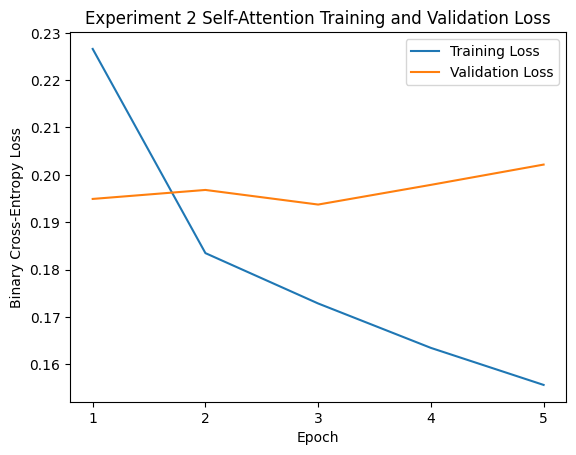

Saved loss curve: task2_sentiment/jiayi/outputs/experiment2_attention_loss_curve_20261003_135109.png


In [ ]:
exp2_loss_curve_path = exp2_output_dir / f"experiment2_attention_loss_curve_{exp2_run_timestamp}.png"
exp2_epochs = range(1, len(exp2_train_losses) + 1)

plt.figure()
plt.plot(exp2_epochs, exp2_train_losses, label="Training Loss")
plt.plot(exp2_epochs, exp2_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Experiment 2 Self-Attention Training and Validation Loss")
plt.xticks(exp2_epochs)
plt.legend()
plt.savefig(exp2_loss_curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved loss curve:", exp2_loss_curve_path)

In [ ]:
exp2_manifest = {
    "task": "task2_sentiment",
    "model": "experiment2_single_head_self_attention",
    "member": MEMBER_NAME,
    "run_id": exp2_run_timestamp,
    "architecture": "Learned Token Embedding + Learned Positional Embedding -> Q/K/V -> Single-Head Self-Attention -> Wo -> Masked Mean Pooling -> Linear -> Sigmoid",
    "config_file": str(config_path),
    "config": config["experiment_2"],
    "raw_log": str(exp2_train_log_path),
    "best_checkpoint": str(exp2_best_checkpoint_path),
    "best_epoch": exp2_best_epoch,
    "best_val_loss": float(exp2_best_val_loss),
    "loss_curve": str(exp2_loss_curve_path),
    "cpu": exp2_cpu_name,
    "gpu": exp2_gpu_name,
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "parameter_count": exp2_parameter_count,
    "training_time_sec": exp2_total_train_seconds,
    "total_run_time_sec": exp2_total_run_time,
    "examples_per_sec": exp2_overall_examples_per_sec,
    "peak_gpu_memory_mb": exp2_peak_memory_mb,
    "environment_file": str(exp2_environment_path),
    "metrics_report": str(Path("task2_sentiment") / MEMBER_NAME / "metrics_report.csv")
}

exp2_manifest_path = exp2_manifest_dir / f"task2_{MEMBER_NAME}_experiment2_attention_manifest_{exp2_run_timestamp}.json"

with open(exp2_manifest_path, "w") as f:
    json.dump(exp2_manifest, f, indent=2)

print("Saved raw log:", exp2_train_log_path)
print("Saved checkpoint:", exp2_best_checkpoint_path)
print("Saved loss curve:", exp2_loss_curve_path)
print("Saved manifest:", exp2_manifest_path)
print("Saved environment:", exp2_environment_path)

Saved raw log: reproducibility/raw_logs/task2_jiayi_experiment2_attention_train_20261003_135109.log
Saved checkpoint: task2_sentiment/jiayi/checkpoints/task2_experiment2_attention_best_20261003_135109.pt
Saved loss curve: task2_sentiment/jiayi/outputs/experiment2_attention_loss_curve_20261003_135109.png
Saved manifest: reproducibility/manifests/task2_jiayi_experiment2_attention_manifest_20261003_135109.json
Saved environment: reproducibility/manifests/task2_jiayi_experiment2_attention_environment_20261003_135109.txt


### Inference

In [36]:
# Best checkpoints from the three official training runs
checkpoint_paths = {
    "baseline": Path("task2_sentiment/jiayi/checkpoints/task2_baseline_meanmax_best_20261004_234803.pt"),
    "experiment_1_mlp": Path("task2_sentiment/jiayi/checkpoints/task2_experiment1_mlp_best_20261002_211627.pt"),
    "experiment_2_attention": Path("task2_sentiment/jiayi/checkpoints/task2_experiment2_attention_best_20261003_135109.pt")
}

for model_name, checkpoint_path in checkpoint_paths.items():
    print(model_name, checkpoint_path, checkpoint_path.exists())

baseline task2_sentiment/jiayi/checkpoints/task2_baseline_meanmax_best_20261004_234803.pt True
experiment_1_mlp task2_sentiment/jiayi/checkpoints/task2_experiment1_mlp_best_20261002_211627.pt True
experiment_2_attention task2_sentiment/jiayi/checkpoints/task2_experiment2_attention_best_20261003_135109.pt True


In [ ]:
def load_model_from_checkpoint(model_name, checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)

    assert checkpoint["vocab_size"] == VOCAB_SIZE
    assert checkpoint["pad_idx"] == PAD_IDX
    assert checkpoint["max_len"] == MAX_LEN

    if model_name == "baseline":
        assert checkpoint["pooling"] == "mean_max"
        model = MeanMaxEmbeddingClassifier(vocab_size=checkpoint["vocab_size"], embed_dim=checkpoint["embedding_dim"], pad_idx=checkpoint["pad_idx"])

    elif model_name == "experiment_1_mlp":
        model = MeanEmbeddingMLPClassifier(vocab_size=checkpoint["vocab_size"], embed_dim=checkpoint["embedding_dim"], hidden_dim_1=checkpoint["hidden_dim_1"], hidden_dim_2=checkpoint["hidden_dim_2"], dropout=checkpoint["dropout"], pad_idx=checkpoint["pad_idx"])

    elif model_name == "experiment_2_attention":
        model = SingleHeadSelfAttentionClassifier(vocab_size=checkpoint["vocab_size"], embed_dim=checkpoint["embedding_dim"], attention_dim=checkpoint["attention_dim"], max_len=checkpoint["max_len"], pad_idx=checkpoint["pad_idx"])

    else:
        raise ValueError(f"Unknown model: {model_name}")

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(device)
    model.eval()

    return model, checkpoint

In [ ]:
def run_test_inference(model, loader):
    all_probabilities = []
    all_labels = []

    model.eval()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        for batch_ids, batch_labels in tqdm(loader, desc="Test inference"):
            batch_ids = batch_ids.to(device)
            probabilities = model(batch_ids).squeeze(1)

            all_probabilities.append(probabilities.cpu().numpy())
            all_labels.append(batch_labels.squeeze(1).numpy())

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    y_prob = np.concatenate(all_probabilities)
    y_true = np.concatenate(all_labels).astype(int)
    examples_per_sec = len(y_true) / elapsed

    return y_true, y_prob, elapsed, examples_per_sec

In [ ]:
test_probabilities = {}
test_inference_stats = {}
test_labels = None

for model_name, checkpoint_path in checkpoint_paths.items():
    print(f"\nRunning test inference: {model_name}")

    model, checkpoint = load_model_from_checkpoint(model_name, checkpoint_path)

    print("Loaded best epoch:", checkpoint["epoch"])
    print("Checkpoint validation loss:", checkpoint["val_loss"])

    y_true, y_prob, inference_time, inference_examples_per_sec = run_test_inference(model, test_loader)

    if test_labels is None:
        test_labels = y_true
    else:
        assert np.array_equal(test_labels, y_true)

    test_probabilities[model_name] = y_prob
    test_inference_stats[model_name] = {
        "inference_time_sec": inference_time,
        "inference_examples_per_sec": inference_examples_per_sec
    }

    print("Test examples:", len(y_prob))
    print("Probability range:", y_prob.min(), "to", y_prob.max())
    print("Inference time:", round(inference_time, 2), "s")
    print("Inference examples/sec:", round(inference_examples_per_sec, 2))

    del model
    del checkpoint

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Running test inference: baseline
Loaded best epoch: 4
Checkpoint validation loss: 0.19524160891345568


Test inference:   0%|          | 0/594 [00:00<?, ?it/s]

Test examples: 38000
Probability range: 3.570164e-19 to 1.0
Inference time: 7.12 s
Inference examples/sec: 5337.2

Running test inference: experiment_1_mlp
Loaded best epoch: 4
Checkpoint validation loss: 0.1898721590084689


Test inference:   0%|          | 0/594 [00:00<?, ?it/s]

Test examples: 38000
Probability range: 7.7274855e-17 to 1.0
Inference time: 7.14 s
Inference examples/sec: 5324.47

Running test inference: experiment_2_attention
Loaded best epoch: 3
Checkpoint validation loss: 0.19371948484863555


Test inference:   0%|          | 0/594 [00:00<?, ?it/s]

Test examples: 38000
Probability range: 4.069044e-11 to 1.0
Inference time: 7.3 s
Inference examples/sec: 5202.66


In [ ]:
prediction_output_dir = Path("task2_sentiment") / MEMBER_NAME / "outputs"
prediction_output_dir.mkdir(parents=True, exist_ok=True)

raw_predictions = pd.DataFrame({
    "example_id": np.arange(len(test_labels)),
    "y_true": test_labels,
    "encoded_length": np.asarray(test_encoded["length"]),
    "baseline_meanmax_prob": test_probabilities["baseline"],
    "experiment_1_mlp_prob": test_probabilities["experiment_1_mlp"],
    "experiment_2_attention_prob": test_probabilities["experiment_2_attention"]
})

raw_predictions_path = prediction_output_dir / "test_raw_predictions.csv"
raw_predictions.to_csv(raw_predictions_path, index=False)

print("Saved:", raw_predictions_path)
print("Shape:", raw_predictions.shape)

display(raw_predictions.head())

Saved: task2_sentiment/jiayi/outputs/test_raw_predictions.csv
Shape: (38000, 6)


,example_id,y_true,encoded_length,baseline_meanmax_prob,experiment_1_mlp_prob,experiment_2_attention_prob
0,0,1,58,0.419917,0.236557,0.129016
1,1,0,28,0.569177,0.414076,0.445325
2,2,1,6,0.965561,0.879681,0.836962
3,3,0,25,0.091126,0.092837,0.272902
4,4,1,80,0.683702,0.624933,0.727146


In [ ]:
print("Rows:", len(raw_predictions))
print("Missing values:", raw_predictions.isna().sum().sum())
print("Labels:", sorted(raw_predictions["y_true"].unique()))

for column in ["baseline_meanmax_prob", "experiment_1_mlp_prob", "experiment_2_attention_prob"]:
    print(column, "min =", raw_predictions[column].min(), "max =", raw_predictions[column].max())

Rows: 38000
Missing values: 0
Labels: [np.int64(0), np.int64(1)]
baseline_meanmax_prob min = 3.5701639980489763e-19 max = 1.0
experiment_1_mlp_prob min = 7.727485548267922e-17 max = 1.0
experiment_2_attention_prob min = 4.069044060028837e-11 max = 1.0


In [ ]:
raw_predictions = pd.read_csv("task2_sentiment/jiayi/outputs/test_raw_predictions.csv")

team_predictions = raw_predictions.rename(columns={
    "example_id": "test_index",
    "y_true": "true",
    "baseline_meanmax_prob": "prob_meanmax",
    "experiment_1_mlp_prob": "prob_mlp",
    "experiment_2_attention_prob": "prob_attention"
})

team_predictions = team_predictions[
    ["test_index", "true", "prob_meanmax", "prob_mlp", "prob_attention"]
]

team_predictions.to_csv(
    "task2_sentiment/jiayi/outputs/test_predictions.csv",
    index=False
)

print(team_predictions.shape)
display(team_predictions.head())

(38000, 5)


,test_index,true,prob_meanmax,prob_mlp,prob_attention
0,0,1,0.419917,0.236557,0.129016
1,1,0,0.569177,0.414076,0.445325
2,2,1,0.965561,0.879681,0.836962
3,3,0,0.091126,0.092837,0.272902
4,4,1,0.683702,0.624933,0.727146


In [21]:
THRESHOLD = 0.5
N_ECE_BINS = 10
N_BOOTSTRAP = 1000

output_dir = Path("task2_sentiment") / MEMBER_NAME / "outputs"
metrics_report_path = Path("task2_sentiment") / MEMBER_NAME / "metrics_report.csv"

raw_predictions = pd.read_csv(output_dir / "test_raw_predictions.csv")

MODEL_PROB_COLS = {
    "baseline": "baseline_meanmax_prob",
    "experiment_1_mlp": "experiment_1_mlp_prob",
    "experiment_2_attention": "experiment_2_attention_prob"
}

y_true = raw_predictions["y_true"].to_numpy().astype(int)

print("Test examples:", len(raw_predictions))
print("Models:", list(MODEL_PROB_COLS.keys()))
print("Decision threshold:", THRESHOLD)

Test examples: 38000
Models: ['baseline', 'experiment_1_mlp', 'experiment_2_attention']
Decision threshold: 0.5


In [22]:
def expected_calibration_error(y_true, y_prob, n_bins=10):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        lower, upper = bin_edges[i], bin_edges[i + 1]
        mask = (y_prob >= lower) & (y_prob <= upper) if i == n_bins - 1 else (y_prob >= lower) & (y_prob < upper)

        if mask.sum() == 0:
            continue

        bin_weight = mask.mean()
        actual_rate = y_true[mask].mean()
        predicted_rate = y_prob[mask].mean()
        ece += bin_weight * abs(actual_rate - predicted_rate)

    return float(ece)

In [23]:
def bootstrap_ci(y_true, y_pred, n_bootstrap=1000, seed=4253):
    rng = np.random.default_rng(seed)
    n = len(y_true)

    accuracies = []
    macro_f1s = []
    mccs = []

    for _ in tqdm(range(n_bootstrap), desc="Bootstrap"):
        idx = rng.integers(0, n, size=n)
        boot_true = y_true[idx]
        boot_pred = y_pred[idx]

        accuracies.append(accuracy_score(boot_true, boot_pred))
        macro_f1s.append(f1_score(boot_true, boot_pred, average="macro", zero_division=0))
        mccs.append(matthews_corrcoef(boot_true, boot_pred))

    return {
        "accuracy_ci_low": np.percentile(accuracies, 2.5),
        "accuracy_ci_high": np.percentile(accuracies, 97.5),
        "macro_f1_ci_low": np.percentile(macro_f1s, 2.5),
        "macro_f1_ci_high": np.percentile(macro_f1s, 97.5),
        "mcc_ci_low": np.percentile(mccs, 2.5),
        "mcc_ci_high": np.percentile(mccs, 97.5)
    }

In [24]:
def compute_metrics(y_true, y_prob):
    y_pred = (y_prob >= THRESHOLD).astype(int)
    results = {"accuracy": accuracy_score(y_true, y_pred)}

    for average in ["macro", "micro", "weighted"]:
        precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=average, zero_division=0)
        results[f"precision_{average}"] = precision
        results[f"recall_{average}"] = recall
        results[f"f1_{average}"] = f1

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    results["confusion_tn"] = tn
    results["confusion_fp"] = fp
    results["confusion_fn"] = fn
    results["confusion_tp"] = tp

    results["roc_auc"] = roc_auc_score(y_true, y_prob)

    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_prob)
    results["pr_auc"] = auc(recall_curve, precision_curve)

    results["mcc"] = matthews_corrcoef(y_true, y_pred)
    results["brier_score"] = brier_score_loss(y_true, y_prob)
    results["ece"] = expected_calibration_error(y_true, y_prob, N_ECE_BINS)

    results.update(bootstrap_ci(y_true, y_pred, N_BOOTSTRAP, SEED))

    return results

In [26]:
metrics_rows = []

for model_name, prob_col in MODEL_PROB_COLS.items():
    print("\nEvaluating:", model_name)

    y_prob = raw_predictions[prob_col].to_numpy()
    row = {"model": model_name, "test_examples": len(y_true), "decision_threshold": THRESHOLD}
    row.update(compute_metrics(y_true, y_prob))
    metrics_rows.append(row)

metrics_report = pd.DataFrame(metrics_rows)

display(metrics_report[[
    "model", "accuracy",
    "precision_macro", "recall_macro", "f1_macro",
    "precision_micro", "recall_micro", "f1_micro",
    "precision_weighted", "recall_weighted", "f1_weighted",
    "roc_auc", "pr_auc", "mcc", "brier_score", "ece"
]].round(4))


Evaluating: baseline


Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]


Evaluating: experiment_1_mlp


Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]


Evaluating: experiment_2_attention


Bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,precision_weighted,recall_weighted,f1_weighted,roc_auc,pr_auc,mcc,brier_score,ece
0,baseline,0.9272,0.9272,0.9272,0.9272,0.9272,0.9272,0.9272,0.9272,0.9272,0.9272,0.9789,0.9789,0.8543,0.0538,0.0096
1,experiment_1_mlp,0.9283,0.9285,0.9283,0.9283,0.9283,0.9283,0.9283,0.9285,0.9283,0.9283,0.9796,0.9797,0.8568,0.0533,0.0093
2,experiment_2_attention,0.9261,0.9262,0.9261,0.9261,0.9261,0.9261,0.9261,0.9262,0.9261,0.9261,0.9790,0.9794,0.8523,0.0546,0.0093


In [31]:
# Slice metrics by raw review length
dataset_folder = Path("task2_sentiment/data/yelp_polarity")
data_for_slices = load_from_disk(str(dataset_folder))

train_texts_for_slices = data_for_slices["train"]["text"]
test_texts_for_slices = data_for_slices["test"]["text"]

raw_train_lengths = np.array([len(text.split()) for text in train_texts_for_slices])
test_raw_lengths = np.array([len(text.split()) for text in test_texts_for_slices])

length_p50 = int(np.percentile(raw_train_lengths, 50))
length_p90 = int(np.percentile(raw_train_lengths, 90))

assert len(test_raw_lengths) == len(raw_predictions)

slice_masks = {
    "short": test_raw_lengths <= length_p50,
    "medium": (test_raw_lengths > length_p50) & (test_raw_lengths <= length_p90),
    "long": test_raw_lengths > length_p90
}

print("Slice boundaries:")
print(f"short: <= {length_p50} words")
print(f"medium: {length_p50 + 1}-{length_p90} words")
print(f"long: > {length_p90} words")

slice_rows = []

for model_name, prob_col in MODEL_PROB_COLS.items():
    y_prob = raw_predictions[prob_col].to_numpy()
    y_pred = (y_prob >= THRESHOLD).astype(int)

    for slice_name, mask in slice_masks.items():
        slice_rows.append({
            "model": model_name,
            "slice": slice_name,
            "n": int(mask.sum()),
            "macro_f1": f1_score(y_true[mask], y_pred[mask], average="macro", zero_division=0),
            "error_rate": np.mean(y_true[mask] != y_pred[mask])
        })

slice_metrics = pd.DataFrame(slice_rows)
slice_metrics.to_csv(output_dir / "slice_metrics.csv", index=False)

display(slice_metrics.round(4))
print("Saved:", output_dir / "slice_metrics.csv")

Slice boundaries:
short: <= 97 words
medium: 98-282 words
long: > 282 words


,model,slice,n,macro_f1,error_rate
0,baseline,short,19040,0.9248,0.0738
1,baseline,medium,15214,0.9298,0.0697
2,baseline,long,3746,0.9102,0.0804
3,experiment_1_mlp,short,19040,0.9266,0.0724
4,experiment_1_mlp,medium,15214,0.9299,0.0694
5,experiment_1_mlp,long,3746,0.9124,0.0777
6,experiment_2_attention,short,19040,0.9267,0.0720
7,experiment_2_attention,medium,15214,0.9247,0.0749
8,experiment_2_attention,long,3746,0.9121,0.0793


Saved: task2_sentiment/jiayi/outputs/slice_metrics.csv


In [32]:
def mcnemar_test(y_true, pred_a, pred_b):
    a_correct = pred_a == y_true
    b_correct = pred_b == y_true

    b = int(np.sum(a_correct & ~b_correct))
    c = int(np.sum(~a_correct & b_correct))
    discordant = b + c

    p_value = 1.0 if discordant == 0 else binomtest(b, n=discordant, p=0.5, alternative="two-sided").pvalue

    return b, c, discordant, p_value

In [33]:
baseline_prob = raw_predictions[MODEL_PROB_COLS["baseline"]].to_numpy()
baseline_pred = (baseline_prob >= THRESHOLD).astype(int)

mcnemar_rows = []

for model_name in ["experiment_1_mlp", "experiment_2_attention"]:
    exp_prob = raw_predictions[MODEL_PROB_COLS[model_name]].to_numpy()
    exp_pred = (exp_prob >= THRESHOLD).astype(int)

    b, c, discordant, p_value = mcnemar_test(y_true, baseline_pred, exp_pred)

    mcnemar_rows.append({
        "baseline_model": "baseline",
        "experimental_model": model_name,
        "baseline_correct_exp_wrong": b,
        "baseline_wrong_exp_correct": c,
        "discordant_pairs": discordant,
        "net_experimental_wins": c - b,
        "p_value": p_value,
        "significant_0.05": p_value < 0.05
    })

mcnemar_results = pd.DataFrame(mcnemar_rows)
mcnemar_results.to_csv(output_dir / "mcnemar_results.csv", index=False)

display(mcnemar_results)
print("Saved:", output_dir / "mcnemar_results.csv")

,baseline_model,experimental_model,baseline_correct_exp_wrong,baseline_wrong_exp_correct,discordant_pairs,net_experimental_wins,p_value,significant_0.05
0,baseline,experiment_1_mlp,538,581,1119,43,0.209259,False
1,baseline,experiment_2_attention,784,745,1529,-39,0.331148,False


Saved: task2_sentiment/jiayi/outputs/mcnemar_results.csv


In [37]:
MANIFEST_TAGS = {
    "baseline": "baseline_meanmax",
    "experiment_1_mlp": "experiment1_mlp",
    "experiment_2_attention": "experiment2_attention"
}

training_rows = []

for model_name, checkpoint_path in checkpoint_paths.items():
    run_id = "_".join(Path(checkpoint_path).stem.split("_")[-2:])
    manifest_path = Path("reproducibility/manifests") / f"task2_{MEMBER_NAME}_{MANIFEST_TAGS[model_name]}_manifest_{run_id}.json"

    with open(manifest_path, "r") as f:
        manifest = json.load(f)

    training_rows.append({
        "model": model_name,
        "parameter_count": manifest["parameter_count"],
        "training_time_sec": manifest["training_time_sec"],
        "training_examples_per_sec": manifest["examples_per_sec"],
        "peak_gpu_memory_mb": manifest["peak_gpu_memory_mb"],
        "cpu": manifest["cpu"],
        "gpu": manifest["gpu"],
        "run_id": manifest["run_id"]
    })

training_stats = pd.DataFrame(training_rows)
display(training_stats)

,model,parameter_count,training_time_sec,training_examples_per_sec,peak_gpu_memory_mb,cpu,gpu,run_id
0,baseline,3840257,533.652210,4722.176643,89.903809,Intel(R) Xeon(R) CPU @ 2.20GHz,NVIDIA A100-SXM4-40GB,20261004_234803
1,experiment_1_mlp,3850369,612.582213,4113.733550,90.789062,Intel(R) Xeon(R) CPU @ 2.20GHz,NVIDIA A100-SXM4-40GB,20261002_211627
2,experiment_2_attention,3892417,586.057525,4299.919189,110.748047,Intel(R) Xeon(R) CPU @ 2.20GHz,NVIDIA A100-SXM4-40GB,20261003_135109


In [38]:
metrics_report = metrics_report.merge(training_stats, on="model", how="left")

display(metrics_report[[
    "model", "accuracy", "f1_macro", "mcc",
    "parameter_count", "training_time_sec",
    "training_examples_per_sec", "peak_gpu_memory_mb"
]].round(4))

,model,accuracy,f1_macro,mcc,parameter_count,training_time_sec,training_examples_per_sec,peak_gpu_memory_mb
0,baseline,0.9272,0.9272,0.8543,3840257,533.6522,4722.1766,89.9038
1,experiment_1_mlp,0.9283,0.9283,0.8568,3850369,612.5822,4113.7335,90.7891
2,experiment_2_attention,0.9261,0.9261,0.8523,3892417,586.0575,4299.9192,110.7480


In [39]:
slice_metrics = pd.read_csv(output_dir / "slice_metrics.csv")

slice_wide = slice_metrics.pivot(index="model", columns="slice", values=["n", "macro_f1", "error_rate"])
slice_wide.columns = [f"slice_{slice_name}_{metric}" for metric, slice_name in slice_wide.columns]
slice_wide = slice_wide.reset_index()

metrics_report = metrics_report.merge(slice_wide, on="model", how="left")

display(slice_wide.round(4))

,model,slice_long_n,slice_medium_n,slice_short_n,slice_long_macro_f1,slice_medium_macro_f1,slice_short_macro_f1,slice_long_error_rate,slice_medium_error_rate,slice_short_error_rate
0,baseline,3746.0,15214.0,19040.0,0.9102,0.9298,0.9248,0.0804,0.0697,0.0738
1,experiment_1_mlp,3746.0,15214.0,19040.0,0.9124,0.9299,0.9266,0.0777,0.0694,0.0724
2,experiment_2_attention,3746.0,15214.0,19040.0,0.9121,0.9247,0.9267,0.0793,0.0749,0.0720


In [40]:
mcnemar_results = pd.read_csv(output_dir / "mcnemar_results.csv")

metrics_report["mcnemar_b"] = np.nan
metrics_report["mcnemar_c"] = np.nan
metrics_report["mcnemar_discordant_pairs"] = np.nan
metrics_report["mcnemar_net_wins"] = np.nan
metrics_report["mcnemar_p_value"] = np.nan
metrics_report["mcnemar_significant_0.05"] = np.nan

for _, row in mcnemar_results.iterrows():
    mask = metrics_report["model"] == row["experimental_model"]
    metrics_report.loc[mask, "mcnemar_b"] = row["baseline_correct_exp_wrong"]
    metrics_report.loc[mask, "mcnemar_c"] = row["baseline_wrong_exp_correct"]
    metrics_report.loc[mask, "mcnemar_discordant_pairs"] = row["discordant_pairs"]
    metrics_report.loc[mask, "mcnemar_net_wins"] = row["net_experimental_wins"]
    metrics_report.loc[mask, "mcnemar_p_value"] = row["p_value"]
    metrics_report.loc[mask, "mcnemar_significant_0.05"] = row["significant_0.05"]

/tmp/ipykernel_1090/2719753726.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'False' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  metrics_report.loc[mask, "mcnemar_significant_0.05"] = row["significant_0.05"]


In [41]:
metrics_report.to_csv(metrics_report_path, index=False)

print("Saved:", metrics_report_path)
print("Shape:", metrics_report.shape)
display(metrics_report.round(4))

Saved: task2_sentiment/jiayi/metrics_report.csv
Shape: (3, 50)


,model,test_examples,decision_threshold,accuracy,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,...,slice_short_macro_f1,slice_long_error_rate,slice_medium_error_rate,slice_short_error_rate,mcnemar_b,mcnemar_c,mcnemar_discordant_pairs,mcnemar_net_wins,mcnemar_p_value,mcnemar_significant_0.05
0,baseline,38000,0.5,0.9272,0.9272,0.9272,0.9272,0.9272,0.9272,0.9272,...,0.9248,0.0804,0.0697,0.0738,NaN,NaN,NaN,NaN,NaN,NaN
1,experiment_1_mlp,38000,0.5,0.9283,0.9285,0.9283,0.9283,0.9283,0.9283,0.9283,...,0.9266,0.0777,0.0694,0.0724,538.0,581.0,1119.0,43.0,0.2093,False
2,experiment_2_attention,38000,0.5,0.9261,0.9262,0.9261,0.9261,0.9261,0.9261,0.9261,...,0.9267,0.0793,0.0749,0.0720,784.0,745.0,1529.0,-39.0,0.3311,False
